In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random

## 1. Realizar el laberinto

Se representa cada compartimento como un nodo y los pasillos como conexiones. El nodo 7 es la comida y el nodo 8 la descarga eléctrica.

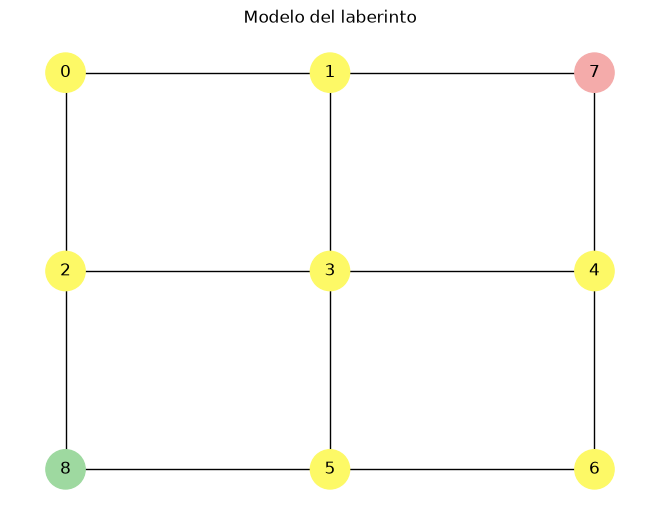

In [16]:
# Crear el laberinto
G = nx.Graph()

# Agregar los compartimentos
G.add_nodes_from([0, 1, 2, 3, 4, 5, 6, 7, 8])

# Agregar las conexiones del laberinto
G.add_edges_from([
    (0,1), (0,2),
    (1,3), (1,7),
    (2,3), (2,8),
    (3,4), (3,5),
    (4,6), (4,7),
    (5,6), (5,8)
])

# Posiciones de los nodos
pos = {
    0:(0,2), 1:(1,2), 7:(2,2),
    2:(0,1), 3:(1,1), 4:(2,1),
    8:(0,0), 5:(1,0), 6:(2,0)
}

colores = [
    "#F4ABAA" if n == 7 else
    "#9ED9A0" if n == 8 else
    "#FDF966" for n in G.nodes()
]

nx.draw(G, pos, with_labels=True,
        node_color=colores, node_size=800)

plt.title("Modelo del laberinto")
plt.show()

## 2. Simulación de una rata

Crear una función para que la rata se mueva aleatoriamente entre los compartimentos hasta llegar a la comida o a la descarga.

In [18]:
COMIDA = 7
DESCARGA = 8

def simular_rata(inicio):

    estado = inicio

    while estado != COMIDA and estado != DESCARGA:

        vecinos = list(G.neighbors(estado))

        estado = random.choice(vecinos)

    return estado

## 3. Prueba de funcionamiento

Realizar 10 recorridos para comprobar que la simulación funciona adecuadamente.

In [19]:
random.seed(2026)

resultados = [simular_rata(0) for _ in range(10)]

print("Resultados de los 10 recorridos:")
print(resultados)

Resultados de los 10 recorridos:
[8, 8, 7, 8, 8, 7, 8, 8, 7, 7]


## 4. Simulación Monte Carlo

Se realizan 100,000 recorridos para observar cuántas ratas llegan a la comida y cuántas reciben una descarga.

In [20]:
N = 100000

finales = [simular_rata(0) for _ in range(N)]

n_comida = finales.count(COMIDA)
n_descarga = finales.count(DESCARGA)

print("Ratas que llegaron a la comida:", n_comida)
print("Ratas que llegaron a la descarga:", n_descarga)
print("Total de simulaciones:", n_comida + n_descarga)

Ratas que llegaron a la comida: 50102
Ratas que llegaron a la descarga: 49898
Total de simulaciones: 100000


## 5. Probabilidad estimada

Calcular la cantidad de ratas que encontraron la comida respecto al total de simulaciones.

In [21]:
p_hat = n_comida / N

print("Probabilidad estimada de encontrar la comida:", p_hat)

Probabilidad estimada de encontrar la comida: 0.50102


## 6. Error estándar e intervalo de confianza

Calcular el error estándar y el intervalo de confianza del 95% para conocer la precisión de la estimación.

In [22]:
ee = np.sqrt(p_hat * (1 - p_hat) / N)

limite_inferior = p_hat - 1.96 * ee
limite_superior = p_hat + 1.96 * ee

print("Error estándar:", ee)

print("Intervalo de confianza al 95%:",
      [limite_inferior, limite_superior])

Error estándar: 0.001581135540047089
Intervalo de confianza al 95%: [np.float64(0.4979209743415077), np.float64(0.5041190256584923)]


## 7. Gráfica de convergencia

En la siguiente gráfica, se puede observar cómo cambia la probabilidad estimada conforme aumenta el número de simulaciones.

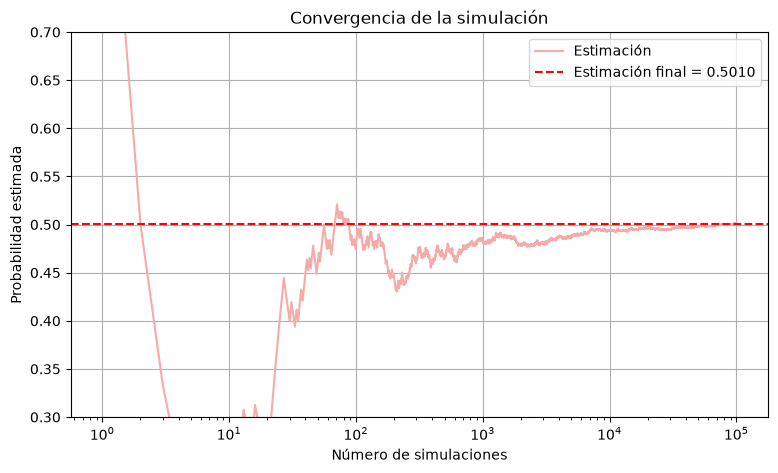

In [23]:
resultados = np.array([1 if f == COMIDA else 0 for f in finales])

estimada = np.cumsum(resultados) / np.arange(1, N + 1)

plt.figure(figsize=(9, 5))

plt.plot(range(1, N + 1), estimada,
         color="#F4ABAA", label="Estimación")

plt.axhline(p_hat, color="r", linestyle="--",
            label=f"Estimación final = {p_hat:.4f}")

plt.xscale("log")
plt.ylim(0.3, 0.7)

plt.xlabel("Número de simulaciones")
plt.ylabel("Probabilidad estimada")
plt.title("Convergencia de la simulación")

plt.legend()
plt.grid()
plt.show()

In [24]:
print("CONCLUSIÓN")

print(f"Se realizaron {N:,} simulaciones.")

print(f"La probabilidad de encontrar la comida antes "
      f"de recibir una descarga es aproximadamente "
      f"{p_hat:.4f}.")

print(f"Es decir, {p_hat*100:.2f}%.")

CONCLUSIÓN
Se realizaron 100,000 simulaciones.
La probabilidad de encontrar la comida antes de recibir una descarga es aproximadamente 0.5010.
Es decir, 50.10%.
